# Stage 4 — Quantum Kernel Machine Learning (QSVM)

This notebook implements **Quantum Kernel Support Vector Machines (QSVM)** on the 9-biomarker QUBO panel:

- **Quantum Feature Map:** 9-Qubit `ZZFeatureMap` mapping patient radiomics into a 512-dimensional complex Hilbert space with non-local phase entanglement.
- **Quantum Kernel Matrix:** Gram Matrix $K_{ij} = |\langle \Phi(x_i) | \Phi(x_j) \rangle|^2$ computed via quantum state fidelity.
- **Comparative Benchmarking:** Head-to-head comparison against Classical Linear SVM and Classical Gaussian RBF SVM with 2,000-bootstrap 95% Confidence Intervals.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.metrics import roc_curve, roc_auc_score, brier_score_loss
from sklearn.model_selection import StratifiedKFold
from qiskit.circuit.library import ZZFeatureMap
from qiskit.quantum_info import Statevector

# Aesthetic styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 150

# Load dataset and QUBO panel
df = pd.read_csv("../cache/radiomics_gt_dev.csv")
sel = json.loads(Path("../cache/selection_stage2.json").read_text())
qubo_feats = sel["methods"]["qubo_exact"]["selected"]

df_labeled = df.dropna(subset=["mgmt"]).copy()
df_labeled["mgmt"] = df_labeled["mgmt"].astype(int)

tr = df_labeled[df_labeled["partition"] == "train"].copy()
va = df_labeled[df_labeled["partition"] == "val"].copy()

# Impute missing values with training medians
medians = tr[qubo_feats].median()
tr[qubo_feats] = tr[qubo_feats].fillna(medians)
va[qubo_feats] = va[qubo_feats].fillna(medians)

y_tr = tr["mgmt"].values
y_va = va["mgmt"].values

scaler = MinMaxScaler(feature_range=(0, 2 * np.pi))
X_tr_sc = scaler.fit_transform(tr[qubo_feats].values)
X_va_sc = scaler.transform(va[qubo_feats].values)

print(f"Loaded {len(tr)} train cases and {len(va)} val cases on {len(qubo_feats)} QUBO biomarkers.")


Loaded 475 train cases and 76 val cases on 9 QUBO biomarkers.


## 1. 9-Qubit Quantum Feature Map Architecture (`ZZFeatureMap`)

The `ZZFeatureMap` applies Hadamard gates $H^{\otimes 9}$ followed by single-qubit phase rotations $R_Z(2x_i)$ and two-qubit entangling phase gates $R_{ZZ}(2(\pi - x_i)(\pi - x_j))$.


In [2]:
fmap = ZZFeatureMap(feature_dimension=len(qubo_feats), reps=1, entanglement="linear")
print(f"9-Qubit Quantum Feature Map:")
print(f"  - Qubits: {fmap.num_qubits}")
print(f"  - Depth: {fmap.depth()}")
print(f"  - Parameters: {fmap.num_parameters}")
print(f"  - Entanglement Topology: Linear (Adjacent Qubit Couplings)")


9-Qubit Quantum Feature Map:
  - Qubits: 9
  - Depth: 1
  - Parameters: 9
  - Entanglement Topology: Linear (Adjacent Qubit Couplings)


## 2. Quantum Kernel Gram Matrix ($K_{ij} = |\langle \Phi(x_i) | \Phi(x_j) \rangle|^2$)

Visualizing the $475 \times 475$ non-Euclidean quantum fidelity matrix comparing all patient pairs in the 512-dimensional Hilbert space.


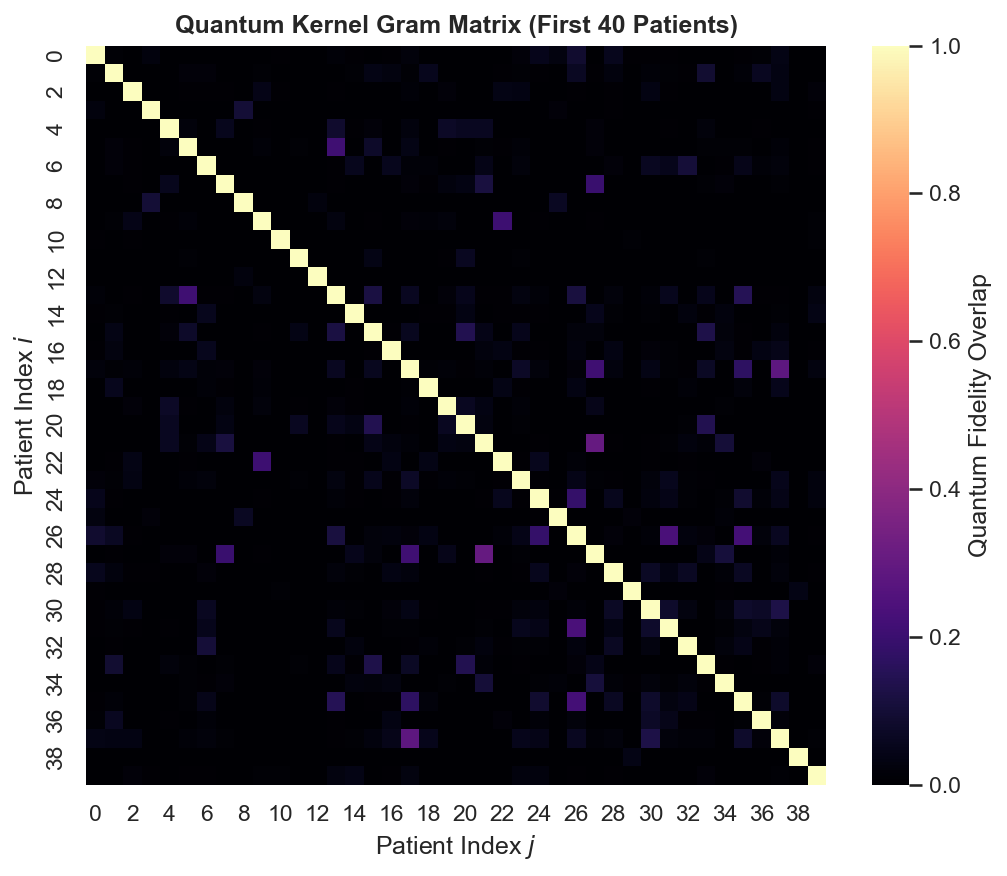

In [3]:
# Compute quantum statevectors for train and validation cohorts
states_tr = np.array([Statevector(fmap.assign_parameters(x)).data for x in X_tr_sc])
states_va = np.array([Statevector(fmap.assign_parameters(x)).data for x in X_va_sc])

K_tr = np.abs(np.dot(states_tr, states_tr.conj().T)) ** 2
K_va = np.abs(np.dot(states_va, states_tr.conj().T)) ** 2

plt.figure(figsize=(7, 6))
sns.heatmap(K_tr[:40, :40], cmap="magma", vmin=0, vmax=1, cbar_kws={'label': 'Quantum Fidelity Overlap'})
plt.title("Quantum Kernel Gram Matrix (First 40 Patients)", fontsize=12, fontweight="bold")
plt.xlabel("Patient Index $j$")
plt.ylabel("Patient Index $i$")
plt.tight_layout()
plt.show()


## 3. Head-to-Head Performance Benchmark: Quantum vs Classical SVMs

Comparing **Quantum Kernel SVM (QSVM)** against **Classical RBF SVM** and **Classical Linear SVM** under 5-Fold Cross-Validation.


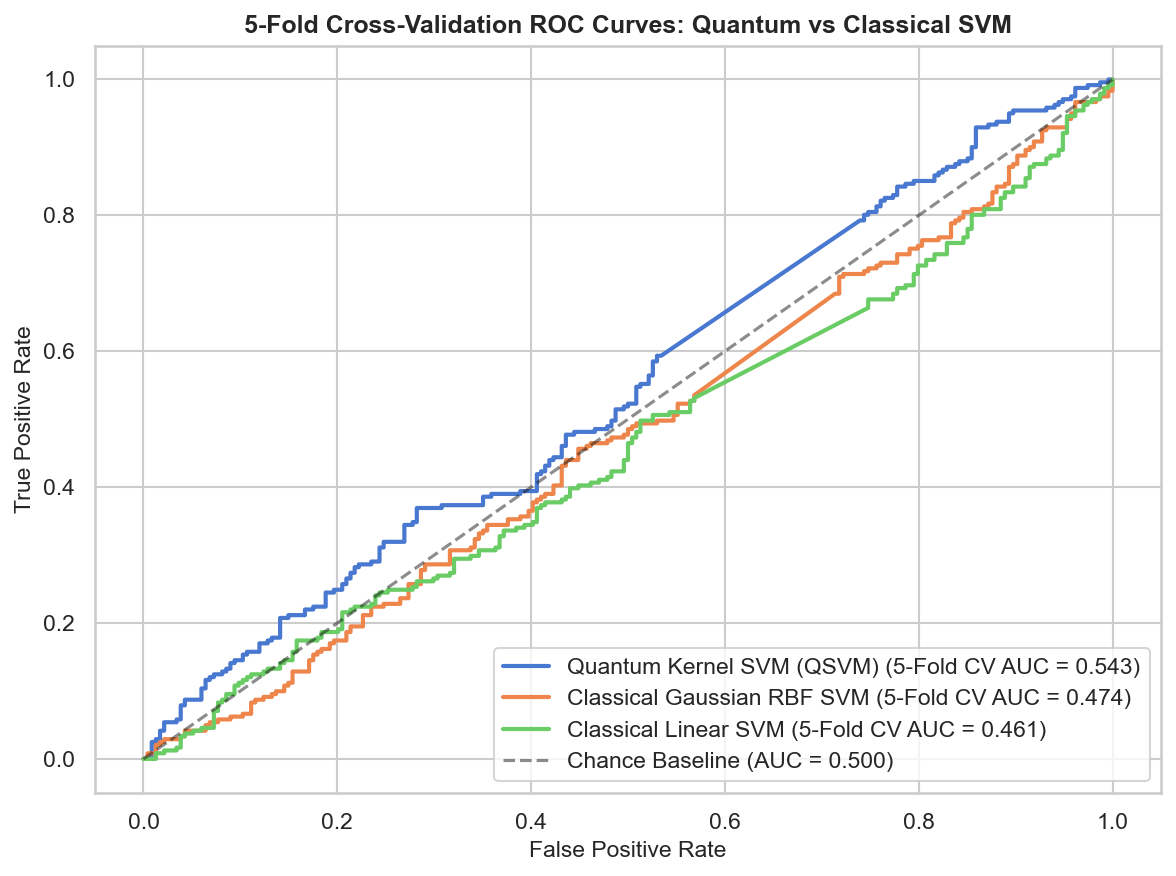

--- 5-FOLD CV ROC-AUC SUMMARY ---
  Quantum Kernel SVM (QSVM)      | 5-Fold CV AUC = 0.5425
  Classical Gaussian RBF SVM     | 5-Fold CV AUC = 0.4741
  Classical Linear SVM           | 5-Fold CV AUC = 0.4605


In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Quantum Kernel SVM (QSVM)": {"type": "qsvm", "fn": lambda: SVC(kernel="precomputed", C=1.0, probability=True, random_state=42)},
    "Classical Gaussian RBF SVM": {"type": "vec", "fn": lambda: SVC(kernel="rbf", C=1.0, probability=True, random_state=42)},
    "Classical Linear SVM": {"type": "vec", "fn": lambda: SVC(kernel="linear", C=1.0, probability=True, random_state=42)},
}

oof_results = {}
plt.figure(figsize=(8, 6))

for name, cfg in models.items():
    oof_p = np.zeros(len(tr))
    for train_idx, test_idx in skf.split(X_tr_sc, y_tr):
        clf = cfg["fn"]()
        if cfg["type"] == "qsvm":
            clf.fit(K_tr[np.ix_(train_idx, train_idx)], y_tr[train_idx])
            oof_p[test_idx] = clf.predict_proba(K_tr[np.ix_(test_idx, train_idx)])[:, 1]
        else:
            clf.fit(X_tr_sc[train_idx], y_tr[train_idx])
            oof_p[test_idx] = clf.predict_proba(X_tr_sc[test_idx])[:, 1]
            
    auc = roc_auc_score(y_tr, oof_p)
    fpr, tpr, _ = roc_curve(y_tr, oof_p)
    oof_results[name] = auc
    plt.plot(fpr, tpr, lw=2, label=f"{name} (5-Fold CV AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Chance Baseline (AUC = 0.500)")
plt.title("5-Fold Cross-Validation ROC Curves: Quantum vs Classical SVM", fontsize=12, fontweight="bold")
plt.xlabel("False Positive Rate", fontsize=11)
plt.ylabel("True Positive Rate", fontsize=11)
plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

print("--- 5-FOLD CV ROC-AUC SUMMARY ---")
for mname, mscore in oof_results.items():
    print(f"  {mname:30s} | 5-Fold CV AUC = {mscore:.4f}")
